# 00 — Dataset Setup and Augmentation Pipeline

**Project:** Bangladeshi Freshwater Fish Image Classification Using CNN and Transfer Learning

**Group Members:**
1. Swapnil Santosh Akhade
2. Mansi Somani
3. Vivek Singh

**Dataset:** Bangladeshi Freshwater Fish Image Dataset (BFF-15)

**Owner:** Swapnil Santosh Akhade (dataset preparation)

---

## Purpose of this notebook

This notebook is the **shared data foundation** for both models:

- `01_custom_cnn.ipynb` (Vivek) — CNN from scratch
- `02_transfer_learning.ipynb` (Mansi) — fine-tuned pretrained model

Both notebooks must load data through this notebook's outputs, so that:

- the **class mapping** is identical,
- the **train / validation / test split** is identical,
- the **augmentation pipeline** is identical.

This guarantees a fair comparison later in `03_comparison.ipynb`.

## What this notebook does

1. Scans the raw dataset and verifies image counts, sizes, and formats.
2. Builds a reproducible, stratified train/validation/test split.
3. Saves the splits to CSV so both model notebooks reuse them.
4. Defines the `tf.data` input pipeline and on-the-fly augmentation.
5. Saves pipeline configuration for reproducibility.

## What this notebook does **not** do

- It does not build, compile, or train any model.
- It does not modify the raw dataset on disk.

## 1. Environment and Imports

We import standard libraries and the shared `data_utils` module from the project root.

In [1]:
import sys, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from PIL import Image
from collections import Counter

import tensorflow as tf

# Make the project root importable so we can `from data_utils import ...`
# PROJECT_ROOT is derived from data_utils.__file__, not from the notebook's
# working directory, so artifacts land in the same place whether this runs from
# the repo root, from notebooks/, or from Google Colab.
sys.path.append(str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from data_utils import (
    PROJECT_ROOT, DATA_DIR, SPLITS_DIR,
    CLASS_NAMES, CLASS_TO_IDX, IDX_TO_CLASS,
    IMG_SIZE, BATCH_SIZE, SEED,
    scan_dataset, content_dedupe,
)

print("TensorFlow:", tf.__version__)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("SPLITS_DIR:", SPLITS_DIR)
print("Num classes:", len(CLASS_NAMES))
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Seed:", SEED)

TensorFlow: 2.21.0
PROJECT_ROOT: D:\GenAI\Practical 1
DATA_DIR: D:\GenAI\Practical 1\data\raw
SPLITS_DIR: D:\GenAI\Practical 1\data\splits
Num classes: 15
Image size: (224, 224)
Batch size: 32
Seed: 42


## 2. Dataset Scanning

We walk `data/raw/` assuming one folder per class.

Expected layout:

data/raw/     
├── GRASS CARP/    
├── ILISH/    
├── KATLA/    
├── ...    
└── TENGRA/    

The scanner returns a DataFrame with one row per image: `filepath`, `label`, `class_name`.

In [2]:
df = scan_dataset()

print("Total images:", len(df))
print()
print("Per-class counts:")
print(df.groupby("class_name").size().reindex(CLASS_NAMES))

# basic integrity
print()
print("Unique labels:", sorted(df["label"].unique()))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate filepaths:", df["filepath"].duplicated().sum())
print("Paths are relative to PROJECT_ROOT:", not Path(df["filepath"].iloc[0]).is_absolute())

Total images: 5577

Per-class counts:
class_name
GRASS CARP     403
ILISH          233
KATLA          427
KOI            434
MAGUR          282
MIRROR CARP    259
MRIGAL         317
PABDA          348
PANGAS         510
PUTI           409
RUI            514
SHOL           296
SILVER CARP    240
TELAPIA        383
TENGRA         522
dtype: int64

Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]
Missing values: 0
Duplicate filepaths: 0
Paths are relative to PROJECT_ROOT: True


## 3. Visual sanity check — one image per class

We display one representative image per class to confirm the folder-to-class mapping is correct.

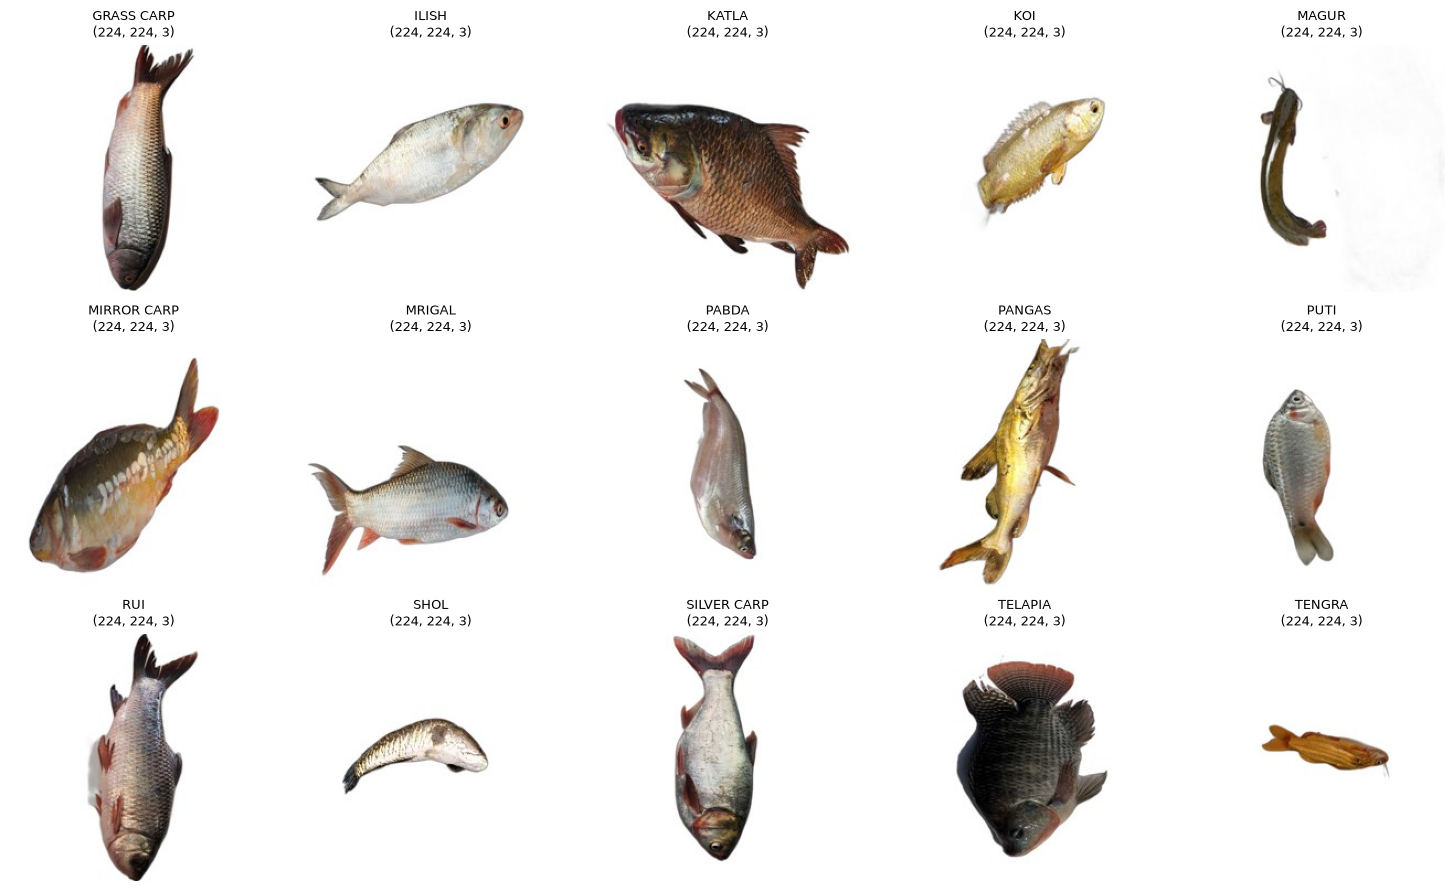

In [3]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
axes = axes.ravel()
for i, cls in enumerate(CLASS_NAMES):
    sample = df[df["class_name"] == cls].iloc[0]
    img = mpimg.imread(str(PROJECT_ROOT / sample["filepath"]))
    axes[i].imshow(img)
    axes[i].set_title(f"{cls}\n{img.shape}", fontsize=9)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

## 4. Image size, mode, and readability check

We sample 200 random images and verify:

- all are the same size,
- all are RGB,
- none are corrupted.

In [4]:
random.seed(SEED)
sample = df.sample(n=200, random_state=SEED)

sizes  = Counter()
modes  = Counter()
broken = []

for _, row in sample.iterrows():
    try:
        with Image.open(row["filepath"]) as im:
            sizes[im.size] += 1
            modes[im.mode] += 1
    except Exception as e:
        broken.append((row["filepath"], str(e)))

print("Top image sizes (w, h):")
for s, c in sizes.most_common(10):
    print(f"  {s}: {c}")

print()
print("Modes:", dict(modes))
print()
print("Broken files:", len(broken))
for path, err in broken[:5]:
    print("  ", path, "->", err)

Top image sizes (w, h):

Modes: {}

Broken files: 200
   data/raw/RUI/RUI_0069.jpg -> [Errno 2] No such file or directory: 'data/raw/RUI/RUI_0069.jpg'
   data/raw/PUTI/PUTI_0315.jpg -> [Errno 2] No such file or directory: 'data/raw/PUTI/PUTI_0315.jpg'
   data/raw/KATLA/KATLA_0089.jpg -> [Errno 2] No such file or directory: 'data/raw/KATLA/KATLA_0089.jpg'
   data/raw/PUTI/PUTI_0158.jpg -> [Errno 2] No such file or directory: 'data/raw/PUTI/PUTI_0158.jpg'
   data/raw/ILISH/ILISH_0066.jpg -> [Errno 2] No such file or directory: 'data/raw/ILISH/ILISH_0066.jpg'


## 5. Save scan summary

We save the per-class counts and totals to `custom_cnn/metrics/dataset_scan.csv`.

This same file is regenerated inside the transfer-learning folder for symmetry later.

In [5]:
CUSTOM_CNN_DIR      = PROJECT_ROOT / "custom_cnn"
TRANSFER_DIR        = PROJECT_ROOT / "transfer_learning"
CUSTOM_METRICS_DIR  = CUSTOM_CNN_DIR / "metrics"
TRANSFER_METRICS_DIR = TRANSFER_DIR / "metrics"

CUSTOM_METRICS_DIR.mkdir(parents=True, exist_ok=True)
TRANSFER_METRICS_DIR.mkdir(parents=True, exist_ok=True)

scan_summary = (
    df.groupby("class_name")
      .size()
      .reindex(CLASS_NAMES)
      .rename("count")
      .reset_index()
)
scan_summary.loc[len(scan_summary)] = ["TOTAL", len(df)]

scan_summary.to_csv(CUSTOM_METRICS_DIR / "dataset_scan.csv", index=False)
scan_summary.to_csv(TRANSFER_METRICS_DIR / "dataset_scan.csv", index=False)

print(scan_summary)
print()
print("Saved:", CUSTOM_METRICS_DIR / "dataset_scan.csv")
print("Saved:", TRANSFER_METRICS_DIR / "dataset_scan.csv")

     class_name  count
0    GRASS CARP    403
1         ILISH    233
2         KATLA    427
3           KOI    434
4         MAGUR    282
5   MIRROR CARP    259
6        MRIGAL    317
7         PABDA    348
8        PANGAS    510
9          PUTI    409
10          RUI    514
11         SHOL    296
12  SILVER CARP    240
13      TELAPIA    383
14       TENGRA    522
15        TOTAL   5577

Saved: D:\GenAI\Practical 1\custom_cnn\metrics\dataset_scan.csv
Saved: D:\GenAI\Practical 1\transfer_learning\metrics\dataset_scan.csv


## 6. Content de-duplication, then stratified train / validation / test split

BFF-15 contains byte-identical photos stored under different filenames, and
some of those copies sit in **different class folders**. Splitting on paths
alone therefore puts one copy in train and its twin in test, which inflates
test accuracy and makes the headline number meaningless.

So we hash the bytes of every image first and keep one representative per
unique image, then split what is left:

- every class keeps the same proportion in every split (stratified 70 / 15 / 15),
- no two images that are the same photo can ever land in different splits,
- both model notebooks train on exactly the same data.

The random seed is fixed (`SEED = 42`), so the split is reproducible.


In [6]:
from sklearn.model_selection import train_test_split

n_raw = len(df)
df = content_dedupe(df)
n_deduped = len(df)
print()

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED,
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED,
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f"Train: {len(train_df)}")
print(f"Val:   {len(val_df)}")
print(f"Test:  {len(test_df)}")
print(f"Total: {len(train_df) + len(val_df) + len(test_df)}")

content-dedupe: 5577 images -> 5223 (354 byte-identical copies removed across 282 duplicate groups)

Train: 3656
Val:   783
Test:  784
Total: 5223


## 7. Verify the split

Two checks:

1. **Stratification:** each class should be ~70 / 15 / 15.
2. **No overlap:** no image may appear in more than one split.

In [7]:
train_counts = train_df["class_name"].value_counts().reindex(CLASS_NAMES)
val_counts   = val_df["class_name"].value_counts().reindex(CLASS_NAMES)
test_counts  = test_df["class_name"].value_counts().reindex(CLASS_NAMES)

summary = pd.DataFrame({
    "train": train_counts,
    "val":   val_counts,
    "test":  test_counts,
    "total": train_counts + val_counts + test_counts,
})
summary["train_pct"] = (summary["train"] / summary["total"] * 100).round(1)
print(summary)

             train  val  test  total  train_pct
class_name                                     
GRASS CARP     270   58    58    386       69.9
ILISH          163   35    35    233       70.0
KATLA          295   63    63    421       70.1
KOI            280   60    60    400       70.0
MAGUR          198   42    42    282       70.2
MIRROR CARP    171   37    36    244       70.1
MRIGAL         154   33    33    220       70.0
PABDA          210   45    45    300       70.0
PANGAS         357   76    77    510       70.0
PUTI           264   57    56    377       70.0
RUI            347   74    75    496       70.0
SHOL           207   45    44    296       69.9
SILVER CARP    153   33    33    219       69.9
TELAPIA        268   57    58    383       70.0
TENGRA         319   68    69    456       70.0


In [8]:
train_paths = set(train_df["filepath"])
val_paths   = set(val_df["filepath"])
test_paths  = set(test_df["filepath"])

print("train ∩ val :", len(train_paths & val_paths))
print("train ∩ test:", len(train_paths & test_paths))
print("val   ∩ test:", len(val_paths   & test_paths))
print("union size  :", len(train_paths | val_paths | test_paths))
print("expected    :", len(df))

assert len(train_paths & val_paths)  == 0
assert len(train_paths & test_paths) == 0
assert len(val_paths   & test_paths) == 0
assert len(train_paths | val_paths | test_paths) == len(df)

# Path overlap alone is not enough: two different filenames can hold the same
# photo. Re-verify on content hashes so leakage is actually excluded.
from data_utils import content_hash

def content_keys(frame):
    return {content_hash(p) for p in frame["filepath"]}

tc, vc, ec = content_keys(train_df), content_keys(val_df), content_keys(test_df)
print()
print("by content  train ∩ val :", len(tc & vc))
print("by content  train ∩ test:", len(tc & ec))
print("by content  val   ∩ test:", len(vc & ec))
assert len(tc & vc) == len(tc & ec) == len(vc & ec) == 0, "content duplication across splits survived dedupe"
assert len(tc | vc | ec) == len(df), "unique content count does not match split coverage"

print("Split verified: no path overlap, no content overlap, full coverage.")

train ∩ val : 0
train ∩ test: 0
val   ∩ test: 0
union size  : 5223
expected    : 5223

by content  train ∩ val : 0
by content  train ∩ test: 0
by content  val   ∩ test: 0
Split verified: no path overlap, no content overlap, full coverage.


## 8. Save splits to CSV

These CSVs are the **single source of truth** for both model notebooks.

- `data/splits/train.csv`
- `data/splits/val.csv`
- `data/splits/test.csv`

Notebooks 01 and 02 must load these files and **not** re-split.

In [9]:
train_df.to_csv(SPLITS_DIR / "train.csv", index=False)
val_df.to_csv(SPLITS_DIR   / "val.csv",   index=False)
test_df.to_csv(SPLITS_DIR  / "test.csv",  index=False)

for name in ["train.csv", "val.csv", "test.csv"]:
    p = SPLITS_DIR / name
    print(f"{name:12s} -> {len(pd.read_csv(p)):5d} rows  ({p.stat().st_size} bytes)")

# Written as paths relative to PROJECT_ROOT on purpose: an absolute path
# recorded here would not exist on a teammate's machine or in Colab.


train.csv    ->  3656 rows  (152789 bytes)
val.csv      ->   783 rows  (32755 bytes)
test.csv     ->   784 rows  (32786 bytes)


## 9. `tf.data` input pipeline

The pipeline lives in `data_utils.make_dataset()` so that notebook 00, 01 and
02 cannot drift apart. Its rules:

- images are read from disk and decoded as RGB,
- resized to 224x224 (already that size, but enforced for robustness),
- pixel values scaled to `[0, 1]`,
- augmentation applied **only** to the training set,
- batches prefetched for speed.

**Important for the transfer-learning notebook:** this pipeline scales to `[0, 1]`.
Notebook 02 applies the pretrained model's own preprocessing as a layer inside
the model, so both notebooks consume byte-for-byte the same tensors.


In [10]:
# The real pipeline is in data_utils.py; notebook 00's job is to prove it works.
from data_utils import _load_image, AUTOTUNE

print("IMG_SIZE:", IMG_SIZE, "| BATCH_SIZE:", BATCH_SIZE, "| AUTOTUNE:", AUTOTUNE)

img, lab = _load_image(str(PROJECT_ROOT / df["filepath"].iloc[0]), df["label"].iloc[0])
print("single image ->", tuple(img.shape), img.dtype,
      "range", float(img.numpy().min()), "to", float(img.numpy().max()))


IMG_SIZE: (224, 224) | BATCH_SIZE: 32 | AUTOTUNE: -1
single image -> (224, 224, 3) <dtype: 'float32'> range 0.0 to 1.0


## 10. Augmentation layer

Defined once in `data_utils.get_augmentation()` and applied only to training
data by `get_train_ds()`:

- horizontal flip,
- small rotation (+-18 deg),
- small zoom (+-10%),
- small contrast jitter (+-10%).

These are Keras preprocessing layers, so they run inside the `tf.data`
pipeline and are **disabled at inference**. Notebooks 01 and 02 must not
re-define augmentation; they get it automatically from `get_train_ds()`.


In [11]:
from data_utils import get_augmentation

data_augmentation = get_augmentation()
data_augmentation.summary()


Model: "augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ ?                      │   0 (unbuilt) │
│ (RandomContrast)                │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 11. Build the datasets

`data_utils.get_train_ds / get_val_ds / get_test_ds` read the CSVs just saved
in section 8 — the same entry point notebooks 01 and 02 use.

- `augment=True` and `shuffle=True` only for the training set.
- Building here also verifies the relative paths written to the CSVs resolve.


In [12]:
from data_utils import get_train_ds, get_val_ds, get_test_ds

train_ds = get_train_ds()
val_ds   = get_val_ds()
test_ds  = get_test_ds()

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val   batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test  batches:", tf.data.experimental.cardinality(test_ds).numpy())


Train batches: 115
Val   batches: 25
Test  batches: 25


## 12. Sanity check one batch

Verify shapes, dtype, pixel range, and labels before trusting the pipeline.

In [13]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Pixel range:",
          float(tf.reduce_min(images).numpy()),
          "to",
          float(tf.reduce_max(images).numpy()))
    print("Labels in batch:", sorted(set(labels.numpy().tolist())))

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Pixel range: 0.0 to 1.0
Labels in batch: [0, 1, 2, 3, 4, 7, 8, 9, 10, 11, 12, 13, 14]


## 13. Visualize augmented samples

Confirm the augmentation looks reasonable — fish are still recognizable and upright.

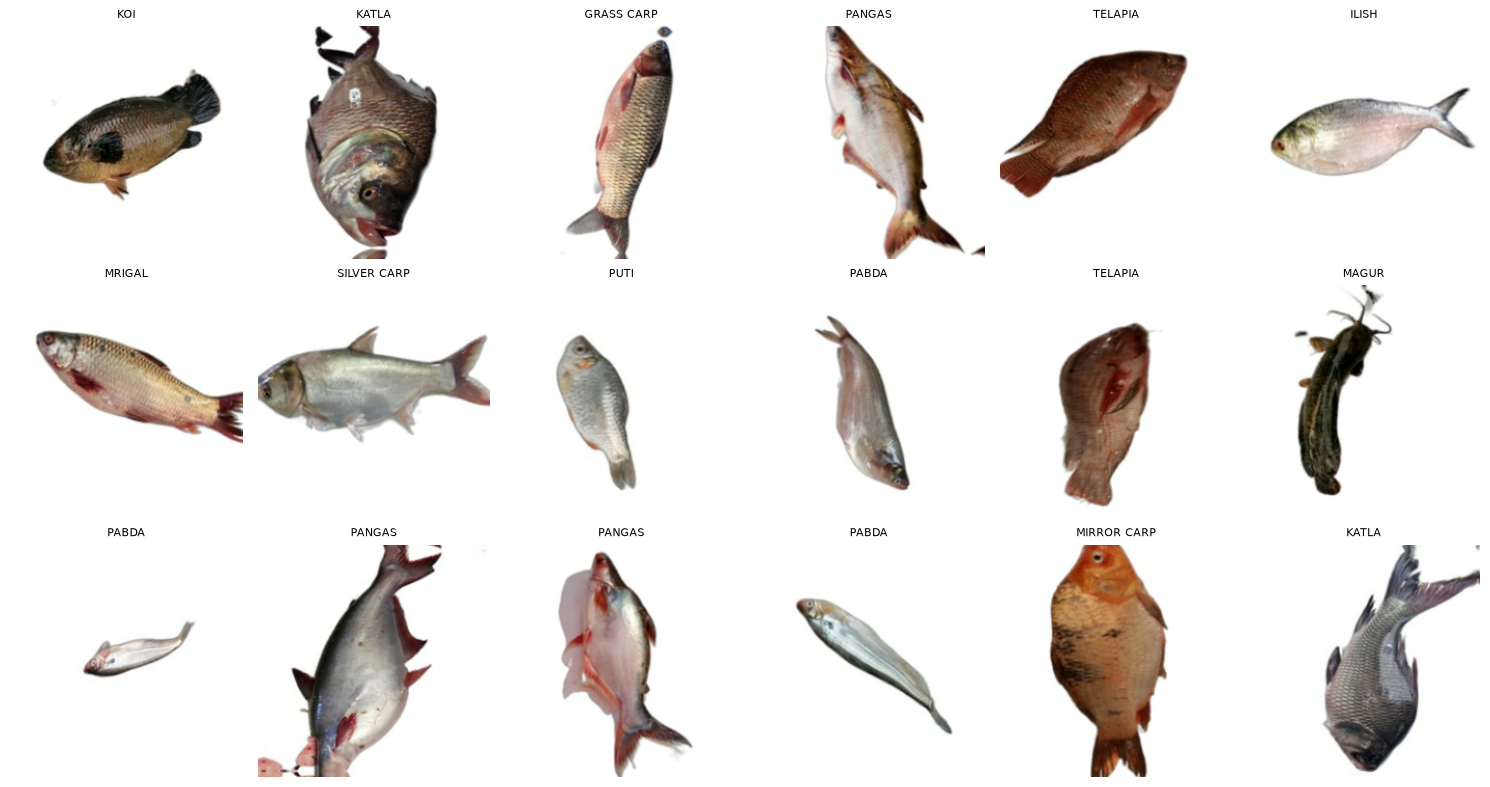

In [14]:
images, labels = next(iter(train_ds))

fig, axes = plt.subplots(3, 6, figsize=(15, 8))
axes = axes.ravel()
for i in range(18):
    axes[i].imshow(images[i].numpy())
    axes[i].set_title(IDX_TO_CLASS[int(labels[i])], fontsize=8)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

## 14. Save pipeline configuration

Both model notebooks must use this exact configuration for a fair comparison.

Saved to `custom_cnn/metrics/pipeline_config.json` and
`transfer_learning/metrics/pipeline_config.json`.

In [15]:
pipeline_info = {
    "img_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "normalization": "scale_to_0_1",
    "augmentation": [
        "horizontal_flip",
        "rotation_0.05",
        "zoom_0.10",
        "contrast_0.10",
    ],
    "train_size": int(len(train_df)),
    "val_size":   int(len(val_df)),
    "test_size":  int(len(test_df)),
    "num_classes": len(CLASS_NAMES),
    "class_names": CLASS_NAMES,
    # dataset accounting: the published BFF-15 count and what we actually trained on
    "raw_images": int(n_raw),
    "duplicate_images_removed": int(n_raw - n_deduped),
    "unique_images": int(n_deduped),
    "split_ratio": [0.70, 0.15, 0.15],
}

for target_dir in [CUSTOM_METRICS_DIR, TRANSFER_METRICS_DIR]:
    out = target_dir / "pipeline_config.json"
    with open(out, "w") as f:
        json.dump(pipeline_info, f, indent=2)
    print("Saved:", out)

print()
print(json.dumps(pipeline_info, indent=2))

Saved: D:\GenAI\Practical 1\custom_cnn\metrics\pipeline_config.json
Saved: D:\GenAI\Practical 1\transfer_learning\metrics\pipeline_config.json

{
  "img_size": [
    224,
    224
  ],
  "batch_size": 32,
  "seed": 42,
  "normalization": "scale_to_0_1",
  "augmentation": [
    "horizontal_flip",
    "rotation_0.05",
    "zoom_0.10",
    "contrast_0.10"
  ],
  "train_size": 3656,
  "val_size": 783,
  "test_size": 784,
  "num_classes": 15,
  "class_names": [
    "GRASS CARP",
    "ILISH",
    "KATLA",
    "KOI",
    "MAGUR",
    "MIRROR CARP",
    "MRIGAL",
    "PABDA",
    "PANGAS",
    "PUTI",
    "RUI",
    "SHOL",
    "SILVER CARP",
    "TELAPIA",
    "TENGRA"
  ],
  "raw_images": 5577,
  "duplicate_images_removed": 354,
  "unique_images": 5223,
  "split_ratio": [
    0.7,
    0.15,
    0.15
  ]
}


## 15. Handoff notes for the model notebooks

Both `01_custom_cnn.ipynb` and `02_transfer_learning.ipynb` must:

1. **Not** re-split the dataset. Load the CSVs via `data_utils.load_splits()`.
2. **Not** apply their own augmentation. Use `get_train_ds()` from `data_utils`.
3. Use the same class mapping: `CLASS_NAMES`, `CLASS_TO_IDX`, `IDX_TO_CLASS`.
4. Import `PROJECT_ROOT` from `data_utils` rather than deriving it from the
   notebook's working directory.
5. Log per-epoch training and validation metrics to their own folder:
   - `custom_cnn/logs/training_log.csv`
   - `transfer_learning/logs/training_log.csv`
6. Save the best checkpoint to:
   - `custom_cnn/best_model/best.keras`
   - `transfer_learning/best_model/best.keras`
7. Save final test metrics through `eval_utils.evaluate_and_save()` so both
   folders produce the identical `final_metrics.json` schema.

`03_comparison.ipynb` then reads those logs and metrics and produces the comparison.

### Preprocessing note for notebook 02

This notebook normalizes to `[0, 1]`. Notebook 02 must convert that to the
range the backbone expects using a **named preprocessing layer inside the
model** (for MobileNetV2: `layers.Rescaling(2.0, offset=-1.0)`, which is exactly
what `preprocess_input` does to `[0, 1]` input). Do not use a `Lambda`: it is
not serialised safely in `.keras` files, so the saved checkpoint would need
`safe_mode=False` to reload. Do not feed `[0, 1]` straight to the backbone
either — that silently degrades the pretrained features.


In [ ]:
import importlib, data_utils
importlib.reload(data_utils)

from data_utils import (
    load_splits, get_train_ds, get_val_ds, get_test_ds,
    get_augmentation, get_class_weights,
    CLASS_NAMES, CLASS_TO_IDX, IDX_TO_CLASS,
)

train_ds = get_train_ds()
val_ds   = get_val_ds()
test_ds  = get_test_ds()

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val   batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test  batches:", tf.data.experimental.cardinality(test_ds).numpy())
print("Class weights:", get_class_weights())

Train batches: 115
Val   batches: 25
Test  batches: 25
Class weights: {0: 0.9027160493827161, 1: 1.4952965235173825, 2: 0.8262146892655368, 3: 0.8704761904761905, 4: 1.230976430976431, 5: 1.4253411306042885, 6: 1.5826839826839827, 7: 1.1606349206349207, 8: 0.6827264239028945, 9: 0.9232323232323232, 10: 0.7024015369836696, 11: 1.1774557165861514, 12: 1.5930283224400872, 13: 0.909452736318408, 14: 0.7640543364681296}


: 